# NB23: Multi-Scale Coupling
## Spatial and Temporal Scale Transfer in RELIC

RELIC uses a category-theoretic vocabulary for scale coupling:
- Area- (or duration-) weighted aggregation $R$ and broadcast disaggregation $P$ are weighted
  adjoints with $RP = I$ and $PR \neq I$ (Proposition 2.1 in
  `docs/source/theory/spatiotemporal_scale_topology.md`; a design interpretation that no RELIC
  component checks at runtime)
- Temporal conservation checking follows `TemporalConfig.conservation_level` (or a per-functor entry in
  `conservation_level_overrides`). `NONE` computes no residual. For the interval mapping laws
  (`MEAN`/`TIME_WEIGHTED_MEAN` on `interval_mean` or `rate`, `SUM` on `rate` or
  `interval_accumulation`, and their uniform disaggregation) `RELAXED` computes the mapping residual
  without a tolerance comparison, `MODERATE` (the field default) compares it with
  `validation.conservation.conservation_tolerance` without blocking, and `STRICT` raises `ValueError`
  on a violation; every level other than `NONE` also needs `q_ref_parameter`. `state_at_boundary`
  mappings and descriptive statistics have no residual law and raise for any level other than `NONE`
- Temporal: fixed-interval sub-daily $\to$ daily over explicit bounds (`TemporalAggregator` rejects `monthly`, `seasonal`, `annual` and `yearly` frequencies)
- Spatial: patch $\to$ hillslope $\to$ basin $\to$ landscape $\to$ regional (the
  `coupling.scales.hierarchy.levels` order) with `ScaleManager.aggregate`, and a conservative
  8x8 $\to$ 4x4 remap with `ScaleManager.regrid_variable`

**Key modules**: `relic.coupling.scales.temporal`, `relic.coupling.scales.spatial`

---

## Architecture Anchor

This notebook is aligned with `docs\source\architecture_overview.md` and the relevant theory/API pages under `docs\source`.
All computations below are intended to use actual RELIC functors, the actual simulator or orchestration layer, and real validation pathways rather than notebook-defined pseudo-process equations.


In [1]:
# Event loop compatibility patch for nbconvert/Jupyter execution
import asyncio
if hasattr(asyncio, "WindowsSelectorEventLoopPolicy"):
    asyncio.set_event_loop_policy(asyncio.WindowsSelectorEventLoopPolicy())

# ---------------------------------------------------------------
# References:
#   Farquhar et al. (1980), Planta -- C3 biochemical photosynthesis model
#   Jones (1999) -- conservative remapping for climate components
#   ESMF and NUOPC clock/state exchange patterns for component coupling
# Mathematical expression:
#   A_net = min(Ac, Aj) - Rd
#   phi_target = sum_i w_ij * phi_source
#   dt_common = LCM(dt_1, dt_2, ..., dt_n)
# Parameter meanings:
#   vcmax25, jmax25, rd25: Farquhar biochemical parameters at 25C
#   patch_areas: fractional areas for hierarchical aggregation
#   hourly_time, daily_time: centered temporal coordinates in hours used by scale-transfer operators
# Units: vcmax25, rd25 [umol CO2 m-2 s-1]; jmax25 [umol e- m-2 s-1]; PAR [umol m-2 s-1];
#   temperature [K]; GPP (gross_primary_productivity) [kg C m-2 s-1]; patch_areas [dimensionless].
# Domain/constraints: explicit half-open time bounds in hours; the ScaleManager ledger tolerance is
#   coupling.scales.defaults.precision.<mode>.tolerance of each call's mode.
# Sign convention: GPP >= 0 is carbon uptake by the canopy.
# ---------------------------------------------------------------

from pathlib import Path
import os
import sys
import warnings
import logging

os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'


def locate_project_root() -> Path:
    candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents, Path(os.environ.get('RELIC_PROJECT_ROOT', Path.cwd())).resolve()]
    for candidate in candidates:
        if (candidate / 'relic').is_dir() and (candidate / 'docs' / 'source' / 'architecture_overview.md').is_file():
            return candidate
    raise FileNotFoundError('Could not locate RELIC project root from the active notebook environment.')


PROJECT_ROOT = locate_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

warnings.filterwarnings('ignore', category=FutureWarning, module=r'torch\\cuda')
warnings.filterwarnings('ignore', message=r'The pynvml package is deprecated.*')
warnings.filterwarnings('ignore', message=r'Consolidated metadata is currently not part in the Zarr format 3 specification.*')

import torch

from relic.parameters import get_global_manager
from relic.core.state import StateManager, UpdateItem
from relic.core.functor.functor_types import SpatialScale, TemporalScale
from relic.scientific.biosphere.photosynthesis.farquhar import FarquharPhotosynthesis
from relic.coupling.scales.types import ScalingStrategy, SpatialQuantityBasis
from relic.coupling.scales.temporal.types import TemporalConfig, TemporalSemantics, ScalingDirection, ConservationLevel
from relic.coupling.scales.temporal.aggregator import TemporalAggregator, AggregationConfig, AggregationMethod
from relic.coupling.scales.temporal.disaggregator import TemporalDisaggregator, DisaggregationConfig, DisaggregationMethod
from relic.coupling.scales.scale_manager import ScaleManager
from relic.coupling.scales.spatial.grid_utils import GridDescriptor
from relic.coupling.protocol.state import State
from relic.coupling.protocol.field import Field
from relic.coupling.protocol.mediator import Mediator
from relic.coupling.protocol.time_stagger import TimeStagger, ClockConfig, TimeUnit
from relic.orchestration.graph_ir import GraphIR
from relic.orchestration.topology_algebra import build_incidence_matrix, compute_left_null_space, compute_rank, compute_cycle_rank

for logger_name in [
    'relic.coupling.scales.hierarchical_strategies',
    'relic.coupling.scales.hierarchical.aggregator',
    'relic.coupling.scales.scale_manager',
    'relic.coupling.scales.spatial.regrid_conservative',
]:
    logging.getLogger(logger_name).setLevel(logging.WARNING)

parameter_manager = get_global_manager()
farquhar_warning_counts: dict[str, int] = {}


def build_photosynthesis_state(par, temperature, leaf_area_index=3.0, co2_ppm: float = 410.0) -> dict:
    par_t = torch.as_tensor(par, dtype=torch.float32).reshape(-1)
    temperature_t = torch.as_tensor(temperature, dtype=torch.float32).reshape(-1)
    lai_t = torch.as_tensor(leaf_area_index, dtype=torch.float32).reshape(-1)
    if lai_t.numel() == 1 and par_t.numel() > 1:
        lai_t = lai_t.repeat(par_t.numel())
    co2_t = torch.full_like(par_t, float(co2_ppm))
    ones = torch.ones_like(par_t)
    return {
        'air_temperature': temperature_t,
        'atmospheric_co2_ppm': co2_t,
        'ppfd': par_t,
        'vcmax_scaling': ones,
        'jmax_scaling': ones,
        'water_stress_factor': ones,
        'temperature_stress_factor': ones,
        'ozone_stress_factor': ones,
        'leaf_area_index': lai_t,
        'vapor_pressure_deficit': torch.full_like(par_t, 1000.0),
        'leaf_water_potential': torch.full_like(par_t, -0.3),
    }


def run_farquhar_response(
    par,
    temperature,
    leaf_area_index=3.0,
    name: str = 'nb23_farquhar',
    vcmax25: float = 58.0,
    jmax25: float = 112.0,
    rd25: float = 1.6,
) -> dict:
    par_t = torch.as_tensor(par, dtype=torch.float32)
    original_shape = par_t.shape
    functor = FarquharPhotosynthesis(
        name=name,
        vcmax25=vcmax25,
        jmax25=jmax25,
        rd25=rd25,
        device=torch.device('cpu'),
        enable_gpu=False,
    )
    with warnings.catch_warnings(record=True) as caught_farquhar_warnings:
        warnings.simplefilter('always', UserWarning)
        outputs = functor(
            build_photosynthesis_state(par_t, temperature, leaf_area_index=leaf_area_index),
            time=0.0,
            dt=3600.0,
        )
    if caught_farquhar_warnings:
        farquhar_warning_counts[name] = farquhar_warning_counts.get(name, 0) + len(caught_farquhar_warnings)
    return {
        key: torch.as_tensor(value.value if isinstance(value, UpdateItem) else value, dtype=torch.float32).reshape(original_shape).detach().cpu()
        for key, value in outputs.items()
    }


torch.manual_seed(42)
days = 30
hours = days * 24
hourly_time = torch.arange(hours, dtype=torch.float32) + 0.5
daily_time = (torch.arange(days, dtype=torch.float32) + 0.5) * 24.0
hourly_bounds = torch.stack([torch.arange(hours, dtype=torch.float32), torch.arange(1, hours + 1, dtype=torch.float32)], dim=1)
daily_bounds = torch.stack([torch.arange(days, dtype=torch.float32) * 24.0, torch.arange(1, days + 1, dtype=torch.float32) * 24.0], dim=1)

hour_fraction = torch.remainder((hourly_time - 0.5) / 24.0, 1.0)
seasonal_factor = 0.85 + 0.15 * torch.sin(2.0 * torch.pi * torch.arange(hours, dtype=torch.float32) / hours)
solar_cycle = torch.clamp(torch.sin(torch.pi * hour_fraction), min=0.0)
par_hourly = 120.0 + 1350.0 * torch.pow(solar_cycle, 1.2) * seasonal_factor
temperature_hourly = 295.0 + 6.5 * torch.sin(2.0 * torch.pi * hour_fraction - 0.6) + 1.5 * torch.sin(2.0 * torch.pi * torch.arange(hours, dtype=torch.float32) / hours)

temporal_outputs = run_farquhar_response(
    par=par_hourly,
    temperature=temperature_hourly,
    leaf_area_index=3.1,
    name='nb23_temporal_series',
)
gpp_hourly_rate = temporal_outputs['gross_primary_productivity']
daily_temperature_mean = temperature_hourly.reshape(days, 24).mean(dim=1)

patch_areas = torch.tensor([0.30, 0.20, 0.35, 0.15], dtype=torch.float32)
patch_par = torch.tensor([1100.0, 1425.0, 980.0, 1280.0], dtype=torch.float32)
patch_temperature = torch.tensor([298.0, 300.0, 297.0, 299.0], dtype=torch.float32)
patch_lai = torch.tensor([2.7, 3.5, 2.3, 3.1], dtype=torch.float32)
patch_outputs = run_farquhar_response(
    par=patch_par,
    temperature=patch_temperature,
    leaf_area_index=patch_lai,
    name='nb23_patch_flux',
)
patch_gpp = patch_outputs['gross_primary_productivity']

field_y, field_x = torch.meshgrid(torch.linspace(0.0, 1.0, 8), torch.linspace(0.0, 1.0, 8), indexing='ij')
par_field = 850.0 + 520.0 * field_x + 180.0 * torch.sin(torch.pi * field_y)
temperature_field = 296.0 + 3.5 * field_y - 1.2 * field_x
lai_field = 2.2 + 1.1 * field_y
field_outputs = run_farquhar_response(
    par=par_field,
    temperature=temperature_field,
    leaf_area_index=lai_field,
    name='nb23_spatial_field',
)
gpp_field_source = field_outputs['gross_primary_productivity']

scale_state_manager = StateManager()
# The facade ledger tolerance is coupling.scales.defaults.precision.<mode>.tolerance of each
# call's mode (ScaleManager.ledger_tolerance); the constructor takes no tolerance.
scale_manager_runtime = ScaleManager(
    device=torch.device('cpu'),
    parameter_manager=parameter_manager,
    state_manager=scale_state_manager,
)
scale_manager_runtime.ensure_ready()
topology_builder = scale_manager_runtime.topology_builder
execution_plan_manifest = scale_manager_runtime.execution_plan()

print('=== RELIC SpatialScale Labels ===')
for scale_entry in SpatialScale:
    print(f'  {scale_entry.name}: {scale_entry.value}')
print()
print('=== RELIC TemporalScale Labels ===')
for scale_entry in TemporalScale:
    print(f'  {scale_entry.name}: {scale_entry.value}')
print()
print(f'  Captured Farquhar diagnostics: {sum(farquhar_warning_counts.values())}')
print(f'  ScaleManager default mode: {scale_manager_runtime.default_mode.value}, '
      f'enforce_conservation={scale_manager_runtime.enforce_conservation}, '
      f'ledger tolerance={scale_manager_runtime.ledger_tolerance():.1e}')
print(f'[OK] Prepared actual temporal series ({hours} hourly steps), patch outputs, and an 8x8 spatial GPP field.')

=== RELIC SpatialScale Labels ===
  POINT: point
  PATCH: patch
  GRID_CELL: grid_cell
  HILLSLOPE: hillslope
  BASIN: basin
  LANDSCAPE: landscape
  GRID_2D: grid_2d
  GRID_3D: grid_3d
  REGIONAL: regional
  GLOBAL: global
  UNKNOWN: unknown

=== RELIC TemporalScale Labels ===
  SECOND: second
  MINUTE: minute
  HOUR: hour
  SUB_DAILY: sub_daily
  DAY: day
  WEEK: week
  MONTH: month
  SEASON: season
  YEAR: year
  STATIC: static
  STEADY_STATE: steady_state
  UNKNOWN: unknown

  Captured Farquhar diagnostics: 0
  ScaleManager default mode: conservative, enforce_conservation=True, ledger tolerance=1.0e-09
[OK] Prepared actual temporal series (720 hourly steps), patch outputs, and an 8x8 spatial GPP field.


## 1. Temporal Aggregation

Aggregate sub-daily flux data to daily values over explicit `source_bounds` and `target_bounds`.
`TemporalAggregator` maps fixed-interval frequencies only: a `source_frequency` or
`target_frequency` containing `monthly`, `seasonal`, `annual` or `yearly` raises `ValueError`.
It also requires `calendar` (`noleap` or `360_day`) and `time_units`.

The temporal law is set by `temporal_semantics` together with `AggregationConfig.method`,
not by an intensive/extensive label. `TemporalConfig.spatial_basis` (a `SpatialQuantityBasis`)
is used only to reject `CATEGORICAL` fields. With source intervals $I_i$, target intervals $J_j$,
overlap $O_{ij} = \lvert I_i \cap J_j \rvert$ and validity mask $v_i$:

- `MEAN` or `TIME_WEIGHTED_MEAN`, allowed for `interval_mean` and `rate` (the output keeps that semantics):
  $y_j = \sum_i v_i O_{ij} x_i \,/\, \sum_i v_i O_{ij}$
- `SUM` on `rate` integrates the rate over each overlap and outputs `interval_accumulation`:
  $y_j = \sum_i v_i O_{ij} r_i$
- `SUM` on `interval_accumulation`: $y_j = \sum_i v_i \,(O_{ij} / \lvert I_i \rvert)\, a_i$
- `MINIMUM`, `MAXIMUM`, `MEDIAN`, `VARIANCE`, `STANDARD_DEVIATION` and `RANGE` require `interval_mean`.

A target whose valid coverage is below the parameter `coupling.scales.temporal.coverage_threshold`
is NaN for these laws. The cell below uses `TemporalSemantics.RATE` with `AggregationMethod.MEAN`,
so the output is a daily mean GPP rate in kg C m-2 s-1. It sets `ConservationLevel.NONE`, so no
conservation residual is computed.


In [2]:
# ---------------------------------------------------------------
# References:
#   CF Conventions 1.8 -- temporal cell methods and aggregation metadata
#   WMO climatological processing guidance for sub-daily to daily summaries
# Mathematical expression:
#   phi_daily = mean(phi_hourly_i)
#   for regular hourly interval means, the daily operator is the arithmetic mean
# Parameter meanings:
#   coverage_threshold: minimum accepted temporal coverage fraction per target period
#     (parameter coupling.scales.temporal.coverage_threshold, read at construction)
#   gpp_hourly_rate: actual Farquhar GPP rate at hourly resolution [kg C m-2 s-1]
# ---------------------------------------------------------------

gpp_rate_aggregator = TemporalAggregator(
    TemporalConfig(
        source_frequency='hourly',
        target_frequency='daily',
        direction=ScalingDirection.UPSCALE,
        spatial_basis=SpatialQuantityBasis.AREA_DENSITY,  # kg C m-2 s-1 per unit ground area
        temporal_semantics=TemporalSemantics.RATE,
        conservation_level=ConservationLevel.NONE,
        device=torch.device('cpu'),
    ),
    AggregationConfig(method=AggregationMethod.MEAN),
)

# Centered hourly coordinates with explicit bounds give every day full coverage; the coverage
# threshold is not a TemporalConfig field and is not overridden here.

gpp_daily_rate_result = gpp_rate_aggregator.aggregate(
    gpp_hourly_rate,
    hourly_time,
    daily_time,
    variable_name='gpp_rate',
    standard_name='gross_primary_productivity',
    units='kg C m-2 s-1',
    time_units='hours since 1970-01-01',
    calendar='noleap',
    source_bounds=hourly_bounds,
    target_bounds=daily_bounds,
    target_units='kg C m-2 s-1',
    measure_units='kg C m-2',
    integration_time_unit='s',
)
gpp_daily_rate = gpp_daily_rate_result.data.detach().cpu()

print('=== Temporal Aggregation with TemporalAggregator ===')
print(f'  Source shape: {tuple(gpp_hourly_rate.shape)}')
print(f'  Target shape: {tuple(gpp_daily_rate.shape)}')
print(f'  Coverage threshold (parameter): {gpp_rate_aggregator.coverage_threshold:.2f}')
print(f'  Minimum valid fraction:  {float(gpp_daily_rate_result.quality_flags.valid_fraction.min().item()):.4f}')
print(f'  Aggregation method:      {gpp_daily_rate_result.diagnostics["aggregation_method"]}')
print(f'  Daily GPP sample:        {[f"{value:.3e}" for value in gpp_daily_rate[:5].tolist()]} kg C m-2 s-1')
print('[OK] Hourly GPP from the actual Farquhar functor was aggregated by RELIC temporal scaling.')

=== Temporal Aggregation with TemporalAggregator ===
  Source shape: (720,)
  Target shape: (30,)
  Coverage threshold (parameter): 0.80
  Minimum valid fraction:  1.0000
  Aggregation method:      mean
  Daily GPP sample:        ['1.636e-07', '1.648e-07', '1.657e-07', '1.664e-07', '1.669e-07'] kg C m-2 s-1
[OK] Hourly GPP from the actual Farquhar functor was aggregated by RELIC temporal scaling.


## 2. Temporal Disaggregation

Disaggregate daily data to hourly intervals with RELIC's `TemporalDisaggregator`.
There are no shape functions or diurnal weight profiles. For `interval_mean`, `rate` and
`interval_accumulation` only `DisaggregationMethod.UNIFORM` runs: a first-order piecewise-constant
mapping over the overlap $O_{ij} = \max(0, \min(a_i^+, b_j^+) - \max(a_i^-, b_j^-))$ between
explicit source bounds $[a_i^-, a_i^+]$ and target bounds $[b_j^-, b_j^+]$. `LINEAR`, `CUBIC_SPLINE`,
`SHAPE_PRESERVING_SPLINE`, `CLIMATOLOGY_DIURNAL`, `EXTERNAL_DRIVER` and `STOCHASTIC` raise `ValueError`.

- `interval_mean` or `rate`: $x_j = \sum_i v_i O_{ij} y_i \,/\, \sum_i v_i O_{ij}$, so every hourly
  interval inside one day receives that day's value.
- `interval_accumulation`: $x_j = \sum_i v_i \,(O_{ij} / \lvert I_i \rvert)\, a_i$, i.e. the daily amount
  is split in proportion to overlap duration.
- `state_at_boundary` does not use the method; it selects boundary values under an explicit
  `exact`, `left` or `right` `state_boundary_policy`, without interpolation.

For `interval_mean`, `rate` and `interval_accumulation` the result diagnostics record
`reconstruction = "piecewise_constant"`. A `state_at_boundary` result has no `reconstruction`
diagnostic; its metadata records `temporal_reconstruction` as `state_exact`, `state_left` or
`state_right`. The cell below copies each daily mean temperature to its 24 hourly intervals:
daily means are preserved, but the within-day waveform is not reconstructed.


In [3]:
# ---------------------------------------------------------------
# References:
#   CF Conventions 1.8 -- temporal interpolation metadata handling
#   Maraun and Widmann (2018) -- temporal downscaling and interpolation practice
# Mathematical expression:
#   phi_hourly = D(phi_daily)
#   roundtrip_error = max(abs(mean_24h(phi_hourly) - phi_daily))
# Parameter meanings:
#   daily_temperature_mean: daily mean driver [K]
#   projection_rmse: mismatch between the disaggregated hourly series and the original hourly driver [K]
# ---------------------------------------------------------------

temperature_disaggregator = TemporalDisaggregator(
    TemporalConfig(
        source_frequency='daily',
        target_frequency='hourly',
        direction=ScalingDirection.DOWNSCALE,
        spatial_basis=SpatialQuantityBasis.INTENSIVE,
        temporal_semantics=TemporalSemantics.INTERVAL_MEAN,
        conservation_level=ConservationLevel.NONE,
        device=torch.device('cpu'),
    ),
    DisaggregationConfig(
        method=DisaggregationMethod.UNIFORM,
        time_dim=-1,
    ),
)

temperature_hourly_result = temperature_disaggregator.disaggregate(
    daily_temperature_mean,
    daily_time,
    hourly_time,
    variable_name='air_temperature',
    standard_name='air_temperature',
    units='K',
    time_units='hours since 1970-01-01',
    calendar='noleap',
    source_bounds=daily_bounds,
    target_bounds=hourly_bounds,
    target_units='K',
    measure_units='K hour',
    integration_time_unit='hour',
)
temperature_hourly_from_daily = temperature_hourly_result.data.detach().cpu()
temperature_roundtrip = temperature_hourly_from_daily.reshape(days, 24).mean(dim=1)
temperature_roundtrip_error = float(torch.abs(temperature_roundtrip - daily_temperature_mean).max().item())
temperature_projection_abs_error = torch.abs(temperature_hourly_from_daily - temperature_hourly)
temperature_projection_max_error = float(torch.max(temperature_projection_abs_error).item())
temperature_projection_rmse = float(torch.sqrt(torch.mean((temperature_hourly_from_daily - temperature_hourly) ** 2)).item())

print('=== Temporal Disaggregation with TemporalDisaggregator ===')
print(f'  Source shape:            {tuple(daily_temperature_mean.shape)}')
print(f'  Target shape:            {tuple(temperature_hourly_from_daily.shape)}')
print(f'  Disaggregation method:   {temperature_disaggregator.disaggregation_config.method.value}')
print(f'  Mean preservation error: {temperature_roundtrip_error:.6f} K')
print(f'  Projection max error:    {temperature_projection_max_error:.6f} K')
print(f'  Projection RMSE:         {temperature_projection_rmse:.6f} K')
print('  Interpretation:          uniform (piecewise-constant) disaggregation preserves daily means but does not reconstruct the sub-daily waveform.')
print('[OK] Daily mean temperature was disaggregated by RELIC and compared against the original hourly driver.')

=== Temporal Disaggregation with TemporalDisaggregator ===
  Source shape:            (30,)
  Target shape:            (720,)
  Disaggregation method:   uniform
  Mean preservation error: 0.000061 K
  Projection max error:    6.591705 K
  Projection RMSE:         4.596641 K
  Interpretation:          uniform (piecewise-constant) disaggregation preserves daily means but does not reconstruct the sub-daily waveform.
[OK] Daily mean temperature was disaggregated by RELIC and compared against the original hourly driver.


## 3. Spatial Scaling

Transfer patch GPP to the hillslope level with `ScaleManager.aggregate` on an explicit
topology (parent map, source areas, target areas). GPP is the catalog variable
`gross_primary_productivity` with `spatial_basis: area_density`, so its law is the
area-weighted mean and the result stays an area density [kg C m-2 s-1]:

$$\bar{x}_{J} = \frac{\sum_{p \in J} A_p \cdot x_p}{A_J}, \qquad A_J = \sum_{p \in J} A_p$$

The facade evaluates the amount ledger $\sum_p x_p A_p = \bar{x}_J A_J$ from the returned field
for every amount variable. It accepts a residual within the tolerance or the floating-point
rounding allowance (`conservation_checker.ledger_acceptance`); in the strict path
(`enforce_conservation` or `strict_conservative`) a larger residual raises, otherwise it is
reported. A variable name that no catalog declares (and no call metadata declares) raises
`KeyError`.


In [4]:
# ---------------------------------------------------------------
# References:
#   Band et al. and RHESSys hierarchy concepts for patch-to-hillslope aggregation
#   RELIC hierarchy mapping parameters under coupling.scales.hierarchy.*
# Mathematical expression:
#   phi_parent = sum_i (A_i * phi_i) / sum_i A_i
# Parameter meanings:
#   patch_gpp: actual patch-scale GPP values from the Farquhar functor
#   patch_areas: patch fractional areas used by the configured topology
# Units: GPP [kg C m-2 s-1] (area density); A_i [dimensionless area fractions].
# Domain/constraints: target area A_J = sum of member areas; ledger sum_i x_i A_i = x_J A_J.
# Sign convention: GPP >= 0 is carbon uptake.
# ---------------------------------------------------------------

patch_topology = {
    'n_source_units': int(patch_gpp.numel()),
    'n_target_units': 1,
    'parent_map': {idx: 0 for idx in range(int(patch_gpp.numel()))},
    'source_areas': patch_areas.tolist(),
    'target_areas': [float(patch_areas.sum().item())],
}
patch_topology = topology_builder.validate_topology(patch_topology, 'aggregate')

hillslope_gpp, patch_aggregate_audit = scale_manager_runtime.aggregate(
    patch_gpp,
    source_scale='patch',
    target_scale='hillslope',
    variables=['gross_primary_productivity'],
    strategy=ScalingStrategy.AREA_WEIGHTED_MEAN,
    topology=patch_topology,
)
hillslope_gpp = hillslope_gpp.detach().cpu()
manual_area_weighted_gpp = float((patch_gpp * patch_areas).sum().item() / patch_areas.sum().item())
aggregation_error = abs(float(hillslope_gpp[0].item()) - manual_area_weighted_gpp)
patch_ledger = patch_aggregate_audit.metadata['conservation_audit']['gross_primary_productivity']

print('=== Spatial Scaling with ScaleManager ===')
print(f'  Patch GPP values:       {[f"{value:.3e}" for value in patch_gpp.tolist()]} kg C m-2 s-1')
print(f'  Patch areas:            {[round(value, 3) for value in patch_areas.tolist()]}')
print(f'  Topology target units:  {patch_topology["n_target_units"]}')
print(f'  Hillslope GPP (RELIC):  {float(hillslope_gpp[0].item()):.6e} kg C m-2 s-1')
print(f'  Manual weighted check:  {manual_area_weighted_gpp:.6e} kg C m-2 s-1')
print(f'  Absolute error:         {aggregation_error:.6e} kg C m-2 s-1')
print(f'  Scaling strategy:       {patch_aggregate_audit.strategy}')
print(f'  Ledger accepted:        {patch_ledger.is_conserved} (relative residual {patch_ledger.relative_error:.3e}, '
      f'tolerance {patch_ledger.tolerance:.1e})')
print('[OK] Patch GPP density from the actual Farquhar module was aggregated with explicit area weights.')

=== Spatial Scaling with ScaleManager ===
  Patch GPP values:       ['1.890e-07', '2.156e-07', '1.684e-07', '2.079e-07'] kg C m-2 s-1
  Patch areas:            [0.3, 0.2, 0.35, 0.15]
  Topology target units:  1
  Hillslope GPP (RELIC):  1.899684e-07 kg C m-2 s-1
  Manual weighted check:  1.899684e-07 kg C m-2 s-1
  Absolute error:         0.000000e+00 kg C m-2 s-1
  Scaling strategy:       ScalingStrategy.AREA_WEIGHTED_MEAN
  Ledger accepted:        True (relative residual 1.870e-08, tolerance 1.0e-09)
[OK] Patch GPP density from the actual Farquhar module was aggregated with explicit area weights.


## 3b. Hierarchical Model Stack: Individual to Regional

The previous cell demonstrated patch-to-hillslope scaling. This section extends the example to the full RELIC spatial hierarchy by importing the real `relic.models.individual`, `patch`, `hillslope`, `basin`, `landscape`, and `regional` configuration modules, then propagating actual Farquhar GPP through a chain of `ScaleManager` aggregations. The model
modules are inventoried (Functor and exposed-variable counts); the aggregation chain uses explicit
topologies (two patches per hillslope, then one parent per level) and the catalog variable
`gross_primary_productivity` at every level, so each step is an area-weighted mean of an area density.

=== Hierarchical RELIC Model Modules ===
  individual | functors= 5 | variables= 7
  patch      | functors=14 | variables=15
  hillslope  | functors=21 | variables=22
  basin      | functors=32 | variables=33
  landscape  | functors=24 | variables=24
  regional   | functors=37 | variables=34

=== Leaf-Level Sample from the Individual Module Context ===
  Individual sample GPP:   ['1.792e-07', '1.936e-07', '1.829e-07', '2.054e-07'] kg C m-2 s-1

=== Patch-to-Regional Hierarchy Chain ===
  Patch GPP values:        ['1.890e-07', '2.156e-07', '1.684e-07', '2.079e-07'] kg C m-2 s-1
  Patch areas:             [0.3, 0.2, 0.35, 0.15]
  Hillslope GPP values:    ['1.997e-07', '1.803e-07'] kg C m-2 s-1
  Hillslope areas:         [0.5, 0.5]
  Basin GPP value:         1.899684e-07 kg C m-2 s-1
  Landscape GPP value:     1.899684e-07 kg C m-2 s-1
  Regional GPP value:      1.899684e-07 kg C m-2 s-1
  Direct weighted mean:    1.899684e-07 kg C m-2 s-1
  Hillslope weighted mean: 1.899684e-07 kg C m-2 

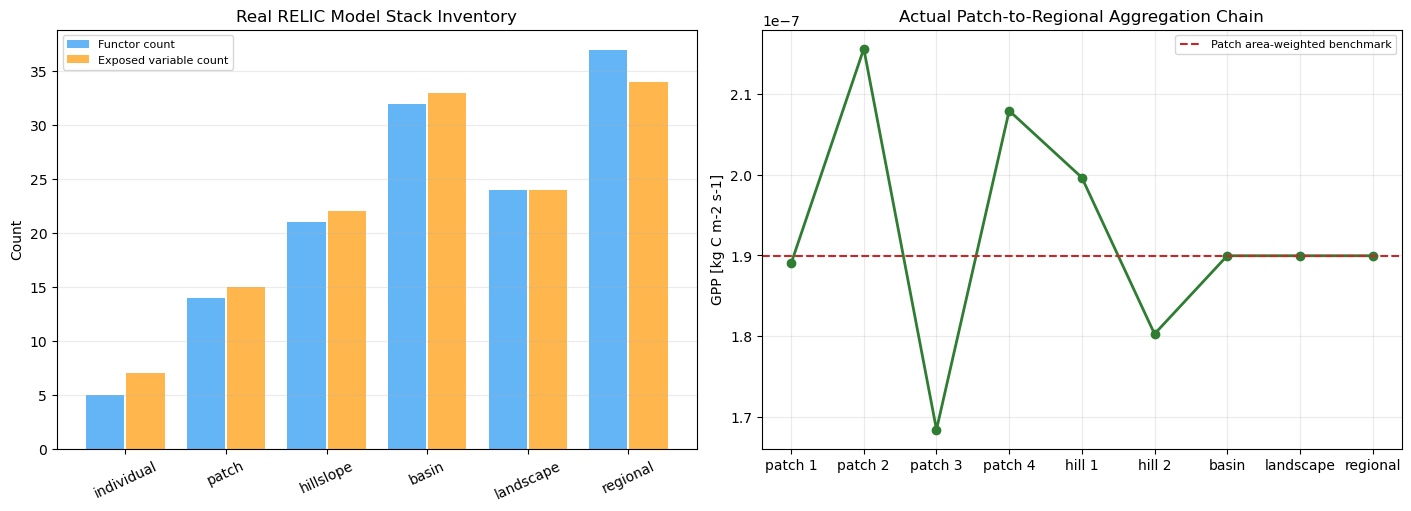

[OK] NB23 hierarchical model plots use real model metadata and ScaleManager aggregates.


In [5]:
# ---------------------------------------------------------------
# References:
#   Band et al. (2001), RHESSys -- hillslope and watershed hierarchy concepts
#   Turner et al. (2001), Landscape Ecology in Theory and Practice -- spatial mosaics and scaling
#   Bonan (2019), Climate Change and Terrestrial Ecosystem Modeling -- ecosystem hierarchy and emergent fluxes
# Mathematical expression:
#   phi_parent = sum_j (A_j * phi_child_j) / sum_j A_j
#   phi_regional = sum_k (A_k * phi_landscape_k) / sum_k A_k
#   epsilon_chain = abs(phi_regional - phi_reference)
# Parameter meanings:
#   patch_chain_areas: patch areas used to initialize the full hierarchy chain
#   hillslope_chain_areas: hillslope areas inherited from patch aggregation target areas
#   chain_reference_mean: direct area-weighted benchmark derived from actual patch GPP values
#   regional_chain_error: mismatch between the final regional aggregate and the patch-scale benchmark
# Units: GPP [kg C m-2 s-1]; areas [dimensionless area fractions]; relative error [dimensionless].
# Domain/constraints: nested strict partition, so the chained area-weighted means equal the direct
#   patch mean up to float32 rounding of the four aggregation steps.
# Sign convention: GPP >= 0 is carbon uptake.
# ---------------------------------------------------------------

import matplotlib.pyplot as plt

from relic.models import individual as model_individual
from relic.models import patch as model_patch
from relic.models import hillslope as model_hillslope
from relic.models import basin as model_basin
from relic.models import landscape as model_landscape
from relic.models import regional as model_regional

model_stack = [
    ('individual', model_individual),
    ('patch', model_patch),
    ('hillslope', model_hillslope),
    ('basin', model_basin),
    ('landscape', model_landscape),
    ('regional', model_regional),
]
model_functor_counts = [len(module.LAYER_FUNCTORS) for _, module in model_stack]
model_variable_counts = [len(module.EXPOSED_VARIABLES) for _, module in model_stack]
model_scale_names = [name for name, _ in model_stack]

individual_par = torch.tensor([1180.0, 1260.0, 1095.0, 1375.0], dtype=torch.float32)
individual_temperature = torch.tensor([297.4, 298.1, 296.9, 299.0], dtype=torch.float32)
individual_lai = torch.tensor([2.4, 2.7, 2.6, 3.0], dtype=torch.float32)
individual_outputs = run_farquhar_response(
    par=individual_par,
    temperature=individual_temperature,
    leaf_area_index=individual_lai,
    name='nb23_individual_inventory_sample',
)
individual_gpp_sample = individual_outputs['gross_primary_productivity'].reshape(-1)

def build_area_topology(parent_map: dict[int, int], source_areas: torch.Tensor) -> dict:
    target_unit_count = max(parent_map.values()) + 1
    target_areas = []
    for target_index in range(target_unit_count):
        members = [source_areas[source_index] for source_index, mapped_target in parent_map.items() if mapped_target == target_index]
        target_areas.append(float(torch.stack(members).sum().item()))
    topology = {
        'n_source_units': int(source_areas.numel()),
        'n_target_units': target_unit_count,
        'parent_map': parent_map,
        'source_areas': source_areas.tolist(),
        'target_areas': target_areas,
    }
    return topology_builder.validate_topology(topology, 'aggregate')

chain_reference_mean = float((patch_gpp * patch_areas).sum().item() / patch_areas.sum().item())
patch_chain_areas = patch_areas.clone().detach().cpu()

patch_to_hillslope_topology = build_area_topology(
    {0: 0, 1: 0, 2: 1, 3: 1},
    patch_chain_areas,
)
hillslope_chain_gpp, patch_hillslope_audit = scale_manager_runtime.aggregate(
    patch_gpp,
    source_scale='patch',
    target_scale='hillslope',
    variables=['gross_primary_productivity'],
    strategy=ScalingStrategy.AREA_WEIGHTED_MEAN,
    topology=patch_to_hillslope_topology,
)
hillslope_chain_gpp = hillslope_chain_gpp.detach().cpu().reshape(-1)
hillslope_chain_areas = torch.tensor(patch_to_hillslope_topology['target_areas'], dtype=torch.float32)
hillslope_weighted_mean = float((hillslope_chain_gpp * hillslope_chain_areas).sum().item() / hillslope_chain_areas.sum().item())

hillslope_to_basin_topology = build_area_topology(
    {0: 0, 1: 0},
    hillslope_chain_areas,
)
basin_chain_gpp, hillslope_basin_audit = scale_manager_runtime.aggregate(
    hillslope_chain_gpp,
    source_scale='hillslope',
    target_scale='basin',
    variables=['gross_primary_productivity'],
    strategy=ScalingStrategy.AREA_WEIGHTED_MEAN,
    topology=hillslope_to_basin_topology,
)
basin_chain_gpp = basin_chain_gpp.detach().cpu().reshape(-1)
basin_chain_areas = torch.tensor(hillslope_to_basin_topology['target_areas'], dtype=torch.float32)

basin_to_landscape_topology = build_area_topology(
    {0: 0},
    basin_chain_areas,
)
landscape_chain_gpp, basin_landscape_audit = scale_manager_runtime.aggregate(
    basin_chain_gpp,
    source_scale='basin',
    target_scale='landscape',
    variables=['gross_primary_productivity'],
    strategy=ScalingStrategy.AREA_WEIGHTED_MEAN,
    topology=basin_to_landscape_topology,
)
landscape_chain_gpp = landscape_chain_gpp.detach().cpu().reshape(-1)
landscape_chain_areas = torch.tensor(basin_to_landscape_topology['target_areas'], dtype=torch.float32)

landscape_to_regional_topology = build_area_topology(
    {0: 0},
    landscape_chain_areas,
)
regional_chain_gpp, landscape_regional_audit = scale_manager_runtime.aggregate(
    landscape_chain_gpp,
    source_scale='landscape',
    target_scale='regional',
    variables=['gross_primary_productivity'],
    strategy=ScalingStrategy.AREA_WEIGHTED_MEAN,
    topology=landscape_to_regional_topology,
)
regional_chain_gpp = regional_chain_gpp.detach().cpu().reshape(-1)
regional_chain_error = abs(float(regional_chain_gpp[0].item()) - chain_reference_mean)
regional_chain_relative_error = regional_chain_error / abs(chain_reference_mean)

# Four float32 area-weighted means: the relative error is rounding-level.
assert regional_chain_relative_error < 1.0e-5

print('=== Hierarchical RELIC Model Modules ===')
for scale_name, module in model_stack:
    print(
        f'  {scale_name:<10} | functors={len(module.LAYER_FUNCTORS):2d} '
        f'| variables={len(module.EXPOSED_VARIABLES):2d}'
    )
print()
print('=== Leaf-Level Sample from the Individual Module Context ===')
print(f'  Individual sample GPP:   {[f"{float(value):.3e}" for value in individual_gpp_sample.tolist()]} kg C m-2 s-1')
print()
print('=== Patch-to-Regional Hierarchy Chain ===')
print(f'  Patch GPP values:        {[f"{float(value):.3e}" for value in patch_gpp.tolist()]} kg C m-2 s-1')
print(f'  Patch areas:             {[round(float(value), 3) for value in patch_chain_areas.tolist()]}')
print(f'  Hillslope GPP values:    {[f"{float(value):.3e}" for value in hillslope_chain_gpp.tolist()]} kg C m-2 s-1')
print(f'  Hillslope areas:         {[round(float(value), 3) for value in hillslope_chain_areas.tolist()]}')
print(f'  Basin GPP value:         {float(basin_chain_gpp[0].item()):.6e} kg C m-2 s-1')
print(f'  Landscape GPP value:     {float(landscape_chain_gpp[0].item()):.6e} kg C m-2 s-1')
print(f'  Regional GPP value:      {float(regional_chain_gpp[0].item()):.6e} kg C m-2 s-1')
print(f'  Direct weighted mean:    {chain_reference_mean:.6e} kg C m-2 s-1')
print(f'  Hillslope weighted mean: {hillslope_weighted_mean:.6e} kg C m-2 s-1')
print(f'  Absolute chain error:    {regional_chain_error:.6e} kg C m-2 s-1')
print(f'  Relative chain error:    {regional_chain_relative_error:.6e}')
print(f'  Aggregation strategies:  {patch_hillslope_audit.strategy}, {hillslope_basin_audit.strategy}, {basin_landscape_audit.strategy}, {landscape_regional_audit.strategy}')
print('[OK] Actual patch Farquhar fluxes were propagated through the RELIC hierarchy to regional scale.')

hierarchy_fig, hierarchy_axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)

ax = hierarchy_axes[0]
functor_positions = torch.arange(len(model_scale_names), dtype=torch.float32)
ax.bar(functor_positions.tolist(), model_functor_counts, width=0.38, color='#64b5f6', label='Functor count')
ax.bar((functor_positions + 0.40).tolist(), model_variable_counts, width=0.38, color='#ffb74d', label='Exposed variable count')
ax.set_xticks((functor_positions + 0.20).tolist())
ax.set_xticklabels(model_scale_names, rotation=25)
ax.set_ylabel('Count')
ax.set_title('Real RELIC Model Stack Inventory')
ax.grid(True, alpha=0.25, axis='y')
ax.legend(fontsize=8)

ax = hierarchy_axes[1]
chain_unit_names = ['patch 1', 'patch 2', 'patch 3', 'patch 4', 'hill 1', 'hill 2', 'basin', 'landscape', 'regional']
chain_unit_values = [
    *[float(value) for value in patch_gpp.tolist()],
    *[float(value) for value in hillslope_chain_gpp.tolist()],
    float(basin_chain_gpp[0].item()),
    float(landscape_chain_gpp[0].item()),
    float(regional_chain_gpp[0].item()),
]
ax.plot(chain_unit_names, chain_unit_values, marker='o', linewidth=2.0, color='#2e7d32')
ax.axhline(chain_reference_mean, color='#c62828', linestyle='--', linewidth=1.5, label='Patch area-weighted benchmark')
ax.set_ylabel('GPP [kg C m-2 s-1]')
ax.set_title('Actual Patch-to-Regional Aggregation Chain')
ax.grid(True, alpha=0.25)
ax.legend(fontsize=8)

plt.show()
print('[OK] NB23 hierarchical model plots use real model metadata and ScaleManager aggregates.')

## 4. Scale Coupling in the Functor Framework

Scale transfers come from two owners:
1. `ScaleCouplingFunctor` subclasses (`TemporalAggregator`, `TemporalDisaggregator`, the spatial
   regridders). They implement the `ScaleCoupling` abstraction (`upscale`, `downscale`) through the
   bridge class, carry `source_scale`/`target_scale` labels, and can be registered in the dependency
   graph like any Functor.
2. The `ScaleManager` facade (`aggregate`, `disaggregate`, `regrid_variable`). It evaluates the
   amount ledger of every call from the returned field (the strict path raises above the accepted
   residual, other paths report it in the `ScalingAudit`) and never rescales the result.

For area-weighted aggregation $R$ and broadcast disaggregation $P$, $RP = I$
(`aggregate . disaggregate = id` up to rounding) while $PR \neq I$; this weighted-adjoint reading
(Proposition 2.1 of `spatiotemporal_scale_topology.md`) is an interpretation, not a runtime check.


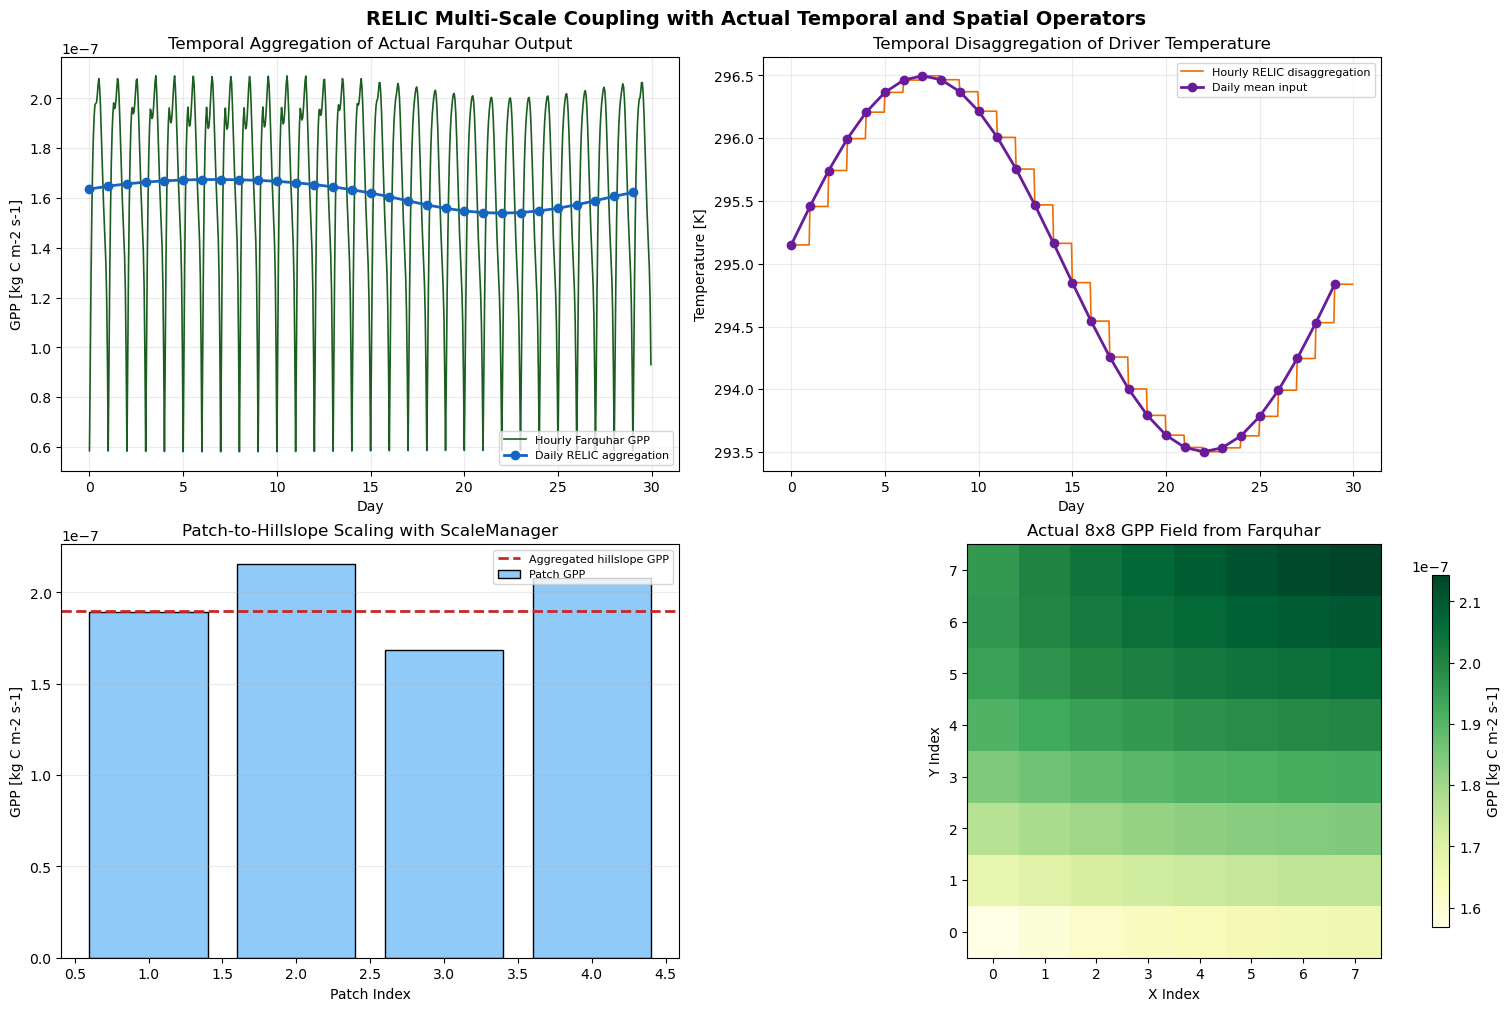

[OK] NB23 visualization uses actual RELIC aggregation, disaggregation, and scale-transfer outputs.


In [6]:
# ---------------------------------------------------------------
# References:
#   CF Conventions 1.8 -- temporal aggregation metadata visualization
#   Jones (1999) -- conservative spatial transfer diagnostics
# Mathematical expression:
#   parent_mean = sum_i A_i * phi_i / sum_i A_i
# Parameter meanings:
#   gpp_daily_rate: daily-scale output produced by TemporalAggregator
#   temperature_hourly_from_daily: hourly series reconstructed by TemporalDisaggregator
# ---------------------------------------------------------------

import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(15, 10), constrained_layout=True)

hourly_day_axis = ((hourly_time - 0.5) / 24.0).tolist()
daily_day_axis = list(range(days))

# Panel 1: Actual hourly GPP and daily aggregated values.
ax = axes[0, 0]
ax.plot(hourly_day_axis, gpp_hourly_rate.tolist(), color='#1b5e20', linewidth=1.2, label='Hourly Farquhar GPP')
ax.plot(daily_day_axis, gpp_daily_rate.tolist(), color='#1565c0', linewidth=2.0, marker='o', label='Daily RELIC aggregation')
ax.set_title('Temporal Aggregation of Actual Farquhar Output')
ax.set_xlabel('Day')
ax.set_ylabel('GPP [kg C m-2 s-1]')
ax.grid(True, alpha=0.25)
ax.legend(fontsize=8)

# Panel 2: Daily mean temperature and hourly disaggregation.
ax = axes[0, 1]
ax.plot(hourly_day_axis, temperature_hourly_from_daily.tolist(), color='#ef6c00', linewidth=1.2, label='Hourly RELIC disaggregation')
ax.plot(daily_day_axis, daily_temperature_mean.tolist(), color='#6a1b9a', linewidth=2.0, marker='o', label='Daily mean input')
ax.set_title('Temporal Disaggregation of Driver Temperature')
ax.set_xlabel('Day')
ax.set_ylabel('Temperature [K]')
ax.grid(True, alpha=0.25)
ax.legend(fontsize=8)

# Panel 3: Patch-scale actual GPP and aggregated hillslope value.
ax = axes[1, 0]
patch_index = list(range(1, patch_gpp.numel() + 1))
ax.bar(patch_index, patch_gpp.tolist(), color='#90caf9', edgecolor='black', label='Patch GPP')
ax.axhline(float(hillslope_gpp[0].item()), color='#c62828', linewidth=2.0, linestyle='--', label='Aggregated hillslope GPP')
ax.set_title('Patch-to-Hillslope Scaling with ScaleManager')
ax.set_xlabel('Patch Index')
ax.set_ylabel('GPP [kg C m-2 s-1]')
ax.grid(True, alpha=0.25, axis='y')
ax.legend(fontsize=8)

# Panel 4: Actual spatial GPP field used for later conservative remapping.
ax = axes[1, 1]
image = ax.imshow(gpp_field_source.tolist(), cmap='YlGn', origin='lower')
ax.set_title('Actual 8x8 GPP Field from Farquhar')
ax.set_xlabel('X Index')
ax.set_ylabel('Y Index')
plt.colorbar(image, ax=ax, shrink=0.85, label='GPP [kg C m-2 s-1]')

fig.suptitle('RELIC Multi-Scale Coupling with Actual Temporal and Spatial Operators', fontsize=14, fontweight='bold')
plt.show()
print('[OK] NB23 visualization uses actual RELIC aggregation, disaggregation, and scale-transfer outputs.')

In [7]:
# Demonstrate the ScaleCoupling abstraction
from relic.core.abstractions import ScaleCoupling

print("=== ScaleCoupling Abstract Base Class ===")
print(f"  Module: {ScaleCoupling.__module__}")
print(f"  Abstract methods: {sorted(ScaleCoupling.__abstractmethods__)}")
print(f"  Public methods:   {[m for m in dir(ScaleCoupling) if not m.startswith('_')]}")

# Abstraction -> bridge -> FunctorBase chain of a concrete scale-coupling operator.
print(f"  TemporalAggregator MRO: {[cls.__name__ for cls in TemporalAggregator.__mro__[:5]]}")

# Show how RELIC coupling/scales implements this
from relic.coupling.scales import scale_manager
print(f"\n  ScaleManager module: {scale_manager.__name__}")
print("[OK] ScaleCoupling contract and bridge chain inspected")


=== ScaleCoupling Abstract Base Class ===
  Module: relic.core.abstractions
  Abstract methods: ['downscale', 'upscale']
  Public methods:   ['downscale', 'get_coupling_metadata', 'get_parameter_value', 'upscale']
  TemporalAggregator MRO: ['TemporalAggregator', 'ScaleCouplingFunctor', 'BridgeParameterMixin', 'ScaleCoupling', 'FunctorBase']

  ScaleManager module: relic.coupling.scales.scale_manager
[OK] ScaleCoupling contract and bridge chain inspected


---
## 5. External Coupling Protocol and Topology Audit

> **Reference:** `docs/source/theory/spatiotemporal_scale_topology.md` Sections 4 (dependency
> graph topology), 9.1 (conservative remapping) and 11.1 (NUOPC clock negotiation)


### 5.1 NUOPC-Style Protocol Objects and Clock Negotiation

This part uses actual NUOPC-style protocol objects (`State`, `Field`, `Mediator`), clock
negotiation (`TimeStagger`), graph incidence auditing, and conservative remapping. The topology
audit is built from the scale-transfer objects used in this notebook.


In [8]:
# ---------------------------------------------------------------
# References:
#   ESMF and NUOPC initialization phases for component coupling
#   RELIC protocol classes in relic.coupling.protocol.*
# Mathematical expression:
#   dt_common = LCM(dt_component_1, dt_component_2, ..., dt_component_n)
# Parameter meanings:
#   lag_seconds: import lag applied during timestamp negotiation
#   negotiated_dt: common coupling step after clock negotiation
# ---------------------------------------------------------------

import_state = State('land_import')
import_state.add_field(
    'surface_par',
    Field(
        name='surface_par',
        data=par_hourly[:24],
        standard_name='surface_downwelling_photosynthetic_photon_flux_in_air',
        units='umol m-2 s-1',
        semantics='forcing',
    ),
    direction='import',
)
import_state.add_field(
    'air_temperature',
    Field(
        name='air_temperature',
        data=daily_temperature_mean,
        standard_name='air_temperature',
        units='K',
        semantics='state',
    ),
    direction='import',
)

export_state = State('land_export')
export_state.add_field(
    'gpp_daily',
    Field(
        name='gpp_daily',
        data=gpp_daily_rate,
        standard_name='gross_primary_productivity',
        units='kg C m-2 s-1',
        semantics='flux',
    ),
    direction='export',
)

mediator = Mediator(import_state=import_state, export_state=export_state)
mediator.advertise({'surface_par', 'air_temperature', 'gpp_daily'})
mediator.realize(validate_all=True)
mediator.data_initialize({'surface_par': par_hourly[:24], 'air_temperature': daily_temperature_mean})
mediator.complete_initialization()

clock_negotiator = TimeStagger(lag_seconds=1800.0, lead_seconds=0.0)
clock_negotiator.register_clock('atmosphere', ClockConfig(time_step=30.0, unit=TimeUnit.MINUTES))
clock_negotiator.register_clock('land', ClockConfig(time_step=1.0, unit=TimeUnit.HOURS))
clock_negotiator.register_clock('hydrology', ClockConfig(time_step=3.0, unit=TimeUnit.HOURS))
negotiated_dt = clock_negotiator.negotiate(strategy='lcm')
clock_warnings = clock_negotiator.validate_temporal_consistency()

print('=== NUOPC-Style Coupling Protocol with Actual RELIC Objects ===')
print(f'  Mediator phase:          {mediator.phase.name}')
print(f'  Import fields:           {[entry["name"] for entry in import_state.manifest()]}')
print(f'  Export fields:           {[entry["name"] for entry in export_state.manifest()]}')
print(f'  Negotiated dt [s]:       {negotiated_dt:.1f}')
print(f'  Atmosphere subcycle:     {clock_negotiator.get_subcycle_ratio("atmosphere")}')
print(f'  Land subcycle:           {clock_negotiator.get_subcycle_ratio("land")}')
print(f'  Hydrology subcycle:      {clock_negotiator.get_subcycle_ratio("hydrology")}')
print(f'  Execution plan steps:    {len(execution_plan_manifest.get("steps", []))}')
print(f'  Clock warnings:          {clock_warnings}')
print('[OK] Protocol phases, state manifests, and clock negotiation come from actual RELIC classes.')

=== NUOPC-Style Coupling Protocol with Actual RELIC Objects ===
  Mediator phase:          READY
  Import fields:           ['surface_par', 'air_temperature']
  Export fields:           ['gpp_daily']
  Negotiated dt [s]:       10800.0
  Atmosphere subcycle:     6
  Land subcycle:           3
  Hydrology subcycle:      1
  Execution plan steps:    5
  Clock warnings:          []
[OK] Protocol phases, state manifests, and clock negotiation come from actual RELIC classes.


### 5.2 Topology Audit of the Scale Graph

This section audits the coupling graph of the scale-transfer steps used in this notebook.

The audit uses the RELIC graph-algebra utilities:

$$B[i, j] = \begin{cases}
-1 & \text{if link } j \text{ leaves node } i \\
+1 & \text{if link } j \text{ enters node } i \\
0 & \text{otherwise}
\end{cases}$$

From the incidence matrix $B$, we compute:

- `rank(B)`: effective coupling dimension
- `cycle_rank(B)`: independent cycle count in the scale graph
- `ker(B^T)`: null combinations of software-graph node coordinates; not a physical ledger

The same incidence-matrix analysis is what `compile_graph(..., include_topology=True)` reports as
the topology signature of a compiled graph. Physical conservation requires an
actual exchange graph, units and support, and executed state/flux ledgers; it
cannot be inferred from this illustrative software graph.

=== Topology Audit of the Tutorial Scale Graph ===
  Incidence matrix shape:  (6, 5)
  Node ids:                ['conservative_regrid', 'daily_aggregate', 'hillslope_aggregate', 'patch_flux', 'protocol_mediator', 'temporal_series']
  Link indices:            [0, 1, 2, 3, 4]
  Rank(B):                 5
  Cycle rank:              0
  Left-null dimension:     1
  Left-null vectors:       [[0.40824830532073975, 0.40824830532073975, 0.40824830532073975, 0.40824830532073975, 0.40824830532073975, 0.40824830532073975]]


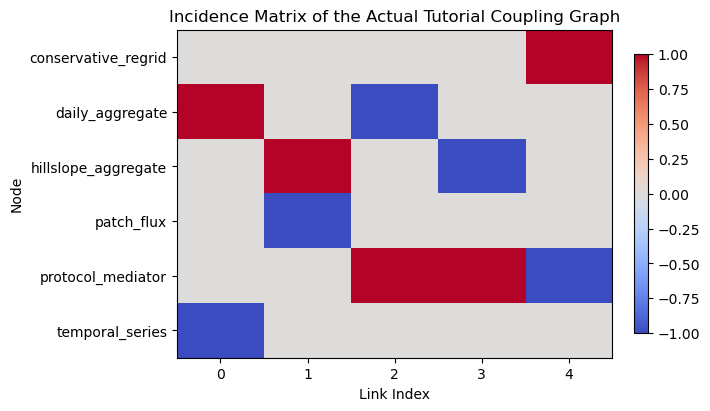

In [9]:
# ---------------------------------------------------------------
# References:
#   Godsil and Royle (2001), Algebraic Graph Theory -- incidence matrices
#   Strang (1988) -- left-null-space interpretation of conservation constraints
# Mathematical expression:
#   B[i, j] = -1 for link source, +1 for link target, 0 otherwise
#   beta_1 = m - rank(B)
# Parameter meanings:
#   B: graph incidence matrix
#   left_null_vectors: software-graph null combinations satisfying B^T x = 0
# ---------------------------------------------------------------

topology_graph = GraphIR.from_dict(
    {
        'schema_version': '1.0',
        'nodes': {
            'temporal_series': {'class_type': 'functor', 'outputs': ['gpp_hourly']},
            'daily_aggregate': {'class_type': 'scale', 'outputs': ['gpp_daily']},
            'patch_flux': {'class_type': 'functor', 'outputs': ['patch_gpp']},
            'hillslope_aggregate': {'class_type': 'scale', 'outputs': ['hillslope_gpp']},
            'protocol_mediator': {'class_type': 'protocol', 'outputs': ['exchange_ready']},
            'conservative_regrid': {'class_type': 'scale', 'outputs': ['gpp_regridded']},
        },
        'links': [
            {'from': {'node': 'temporal_series', 'port': 'gpp_hourly'}, 'to': {'node': 'daily_aggregate', 'port': 'gpp_daily'}},
            {'from': {'node': 'patch_flux', 'port': 'patch_gpp'}, 'to': {'node': 'hillslope_aggregate', 'port': 'hillslope_gpp'}},
            {'from': {'node': 'daily_aggregate', 'port': 'gpp_daily'}, 'to': {'node': 'protocol_mediator', 'port': 'exchange_ready'}},
            {'from': {'node': 'hillslope_aggregate', 'port': 'hillslope_gpp'}, 'to': {'node': 'protocol_mediator', 'port': 'exchange_ready'}},
            {'from': {'node': 'protocol_mediator', 'port': 'exchange_ready'}, 'to': {'node': 'conservative_regrid', 'port': 'gpp_regridded'}},
        ],
    }
)

incidence_matrix_np, topology_node_ids, topology_link_ids = build_incidence_matrix(topology_graph)
incidence_matrix = torch.as_tensor(incidence_matrix_np, dtype=torch.float32)
left_null_vectors = torch.as_tensor(compute_left_null_space(incidence_matrix_np), dtype=torch.float32)
topology_rank = compute_rank(incidence_matrix_np)
topology_cycle_rank = compute_cycle_rank(incidence_matrix_np)

print('=== Topology Audit of the Tutorial Scale Graph ===')
print(f'  Incidence matrix shape:  {tuple(incidence_matrix.shape)}')
print(f'  Node ids:                {topology_node_ids}')
print(f'  Link indices:            {topology_link_ids}')
print(f'  Rank(B):                 {topology_rank}')
print(f'  Cycle rank:              {topology_cycle_rank}')
print(f'  Left-null dimension:     {left_null_vectors.shape[0]}')
print(f'  Left-null vectors:       {left_null_vectors.tolist()}')

fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
heatmap = ax.imshow(incidence_matrix.tolist(), cmap='coolwarm', aspect='auto', vmin=-1.0, vmax=1.0)
ax.set_title('Incidence Matrix of the Actual Tutorial Coupling Graph')
ax.set_xlabel('Link Index')
ax.set_ylabel('Node')
ax.set_yticks(list(range(len(topology_node_ids))))
ax.set_yticklabels(topology_node_ids)
ax.set_xticks(list(range(len(topology_link_ids))))
ax.set_xticklabels([str(index) for index in topology_link_ids])
plt.colorbar(heatmap, ax=ax, shrink=0.85)
plt.show()

### 5.3 Conservative Remapping Verification

For a first-order conservative remap (Jones, 1999) of an area density $x$ with overlap areas
$A_{iJ}$ and $W_{iJ} = A_{iJ} / A_i$, the target value is $y_J = \sum_i x_i A_i W_{iJ} / A_J$ and
the amount on the covered support is kept:

$$\sum_{i} f_i \, x_i A_i = \sum_{J} y_J A_J, \qquad f_i = \sum_J W_{iJ}$$

With full coverage ($f_i = 1$, as for the nested 8x8 $\to$ 4x4 grids below) this is the equality of
the source and target area integrals. With partial coverage the uncovered amount is reported
(`uncovered_source_amount`), never redistributed. Only the conservative method has this ledger
(bilinear and nearest-neighbour remaps do not). `regrid_variable` builds the regridder on the
declared `spatial_basis` (here from the call metadata), audits the covered-support ledger, and raises
under `enforce_conservation` when the ledger is rejected.


=== Conservative Remapping with ScaleManager.regrid_variable ===
  Source field shape:      (8, 8)
  Target field shape:      (4, 4)
  Source area integral:    1.211737e-05 kg C s-1
  Target area integral:    1.211737e-05 kg C s-1
  Conservation error:      0.000000e+00 kg C s-1 (relative 0.000e+00)
  Metadata keys:           ['actual_range', 'conservative', 'coordinates', 'grid_mapping', 'history', 'method']


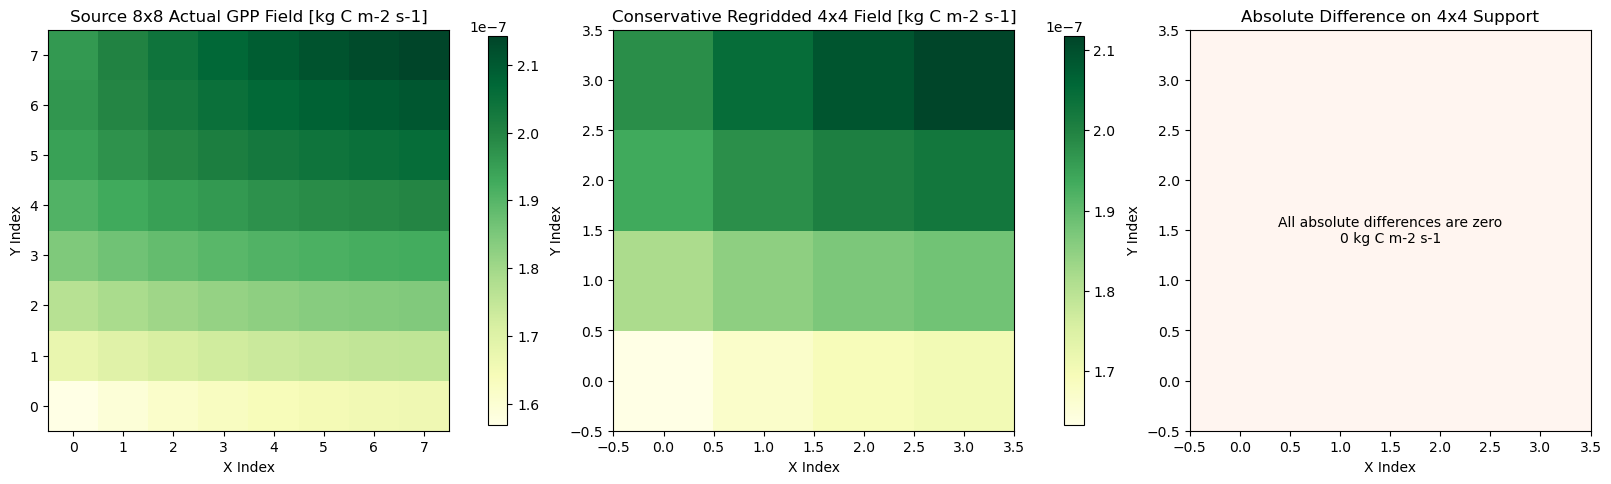

In [10]:
# ---------------------------------------------------------------
# References:
#   Jones (1999) -- first-order conservative remapping
#   ESMF regridding guidance for extensive flux variables
# Mathematical expression:
#   y_J = sum_i x_i A_i W_iJ / A_J with W_iJ = A_iJ / A_i (area density)
#   sum_J y_J A_J = sum_i x_i A_i on full coverage
# Parameter meanings:
#   source_grid, target_grid: GridDescriptor objects used by the spatial regridder
#   source_total, target_total: area-weighted field integrals before and after remapping
# Units: GPP [kg C m-2 s-1]; cell areas [m2] (cartesian grid in m); integrals [kg C s-1].
# Domain/constraints: grids declare their bounds (from shape, spacing, origin); spatial_basis is
#   declared in the call metadata; the regridder ledger uses the ledger tolerance of the call's mode.
# Sign convention: integrals are signed sums; GPP >= 0.
# ---------------------------------------------------------------

source_grid = GridDescriptor(
    shape=(8, 8),
    spacing=(1.0, 1.0),
    origin=(0.0, 0.0),
    grid_type='regular',
    coord_system='cartesian',
)
target_grid = GridDescriptor(
    shape=(4, 4),
    spacing=(2.0, 2.0),
    origin=(0.0, 0.0),
    grid_type='regular',
    coord_system='cartesian',
)
source_grid = scale_manager_runtime.grid_manager.ensure_areas(source_grid)
target_grid = scale_manager_runtime.grid_manager.ensure_areas(target_grid)

gpp_field_regridded, regrid_metadata = scale_manager_runtime.regrid_variable(
    'gross_primary_productivity',
    gpp_field_source,
    source_grid=source_grid,
    target_grid=target_grid,
    strategy='conservative',
    metadata={
        'spatial_basis': 'area_density',
        'semantics': 'flux',
        'units': 'kg C m-2 s-1',
        'conservative': True,
        'per_timestep': True,
        'source_grid': {'shape': source_grid.dims},
        'target_grid': {
            'shape': target_grid.dims,
            'grid_mapping': 'cartesian',
            'lat_name': 'y',
            'lon_name': 'x',
        },
    },
    source_scale='patch',
    target_scale='landscape',
)
gpp_field_regridded = gpp_field_regridded.reshape(target_grid.dims).detach().cpu()

source_total = float((gpp_field_source.reshape(-1) * source_grid.cell_areas.reshape(-1)).sum().item())
target_total = float((gpp_field_regridded.reshape(-1) * target_grid.cell_areas.reshape(-1)).sum().item())
regrid_error = abs(source_total - target_total)

print('=== Conservative Remapping with ScaleManager.regrid_variable ===')
print(f'  Source field shape:      {tuple(gpp_field_source.shape)}')
print(f'  Target field shape:      {tuple(gpp_field_regridded.shape)}')
print(f'  Source area integral:    {source_total:.6e} kg C s-1')
print(f'  Target area integral:    {target_total:.6e} kg C s-1')
print(f'  Conservation error:      {regrid_error:.6e} kg C s-1 (relative {regrid_error / abs(source_total):.3e})')
print(f'  Metadata keys:           {sorted(regrid_metadata.keys())[:6]}')

fig, axes = plt.subplots(1, 3, figsize=(16, 5), constrained_layout=True)
image_0 = axes[0].imshow(gpp_field_source.tolist(), cmap='YlGn', origin='lower')
axes[0].set_title('Source 8x8 Actual GPP Field [kg C m-2 s-1]')
axes[0].set_xlabel('X Index')
axes[0].set_ylabel('Y Index')
plt.colorbar(image_0, ax=axes[0], shrink=0.85)

image_1 = axes[1].imshow(gpp_field_regridded.tolist(), cmap='YlGn', origin='lower')
axes[1].set_title('Conservative Regridded 4x4 Field [kg C m-2 s-1]')
axes[1].set_xlabel('X Index')
axes[1].set_ylabel('Y Index')
plt.colorbar(image_1, ax=axes[1], shrink=0.85)

source_coarse_blocks = gpp_field_source.reshape(4, 2, 4, 2).mean(dim=(1, 3))
error_map = torch.abs(source_coarse_blocks - gpp_field_regridded)
# Display only: retain exact zero errors without an artificial signed color range.
error_max_for_display = float(error_map.max().item())
if error_max_for_display == 0.0:
    from matplotlib.colors import ListedColormap
    image_2 = axes[2].imshow(error_map.tolist(), cmap=ListedColormap(['#fff5f0']), origin='lower', vmin=0.0, vmax=1.0)
    axes[2].text(0.5, 0.5, 'All absolute differences are zero\n0 kg C m-2 s-1', transform=axes[2].transAxes, ha='center', va='center', color='black')
else:
    image_2 = axes[2].imshow(error_map.tolist(), cmap='Reds', origin='lower', vmin=0.0, vmax=error_max_for_display)
    plt.colorbar(image_2, ax=axes[2], shrink=0.85, label='Absolute difference [kg C m-2 s-1]')
axes[2].set_title('Absolute Difference on 4x4 Support')
axes[2].set_xlabel('X Index')
axes[2].set_ylabel('Y Index')

plt.show()

## Summary

| Concept | Actual RELIC path used here | Output |
|---|---|---|
| Temporal aggregation | `TemporalAggregator.aggregate(...)` | Hourly Farquhar GPP aggregated to daily values |
| Temporal disaggregation | `TemporalDisaggregator.disaggregate(...)` | Daily temperature expanded to hourly forcing |
| Hierarchical spatial scaling | `ScaleManager.aggregate(...)` + `TopologyBuilder` | Patch GPP (area density) aggregated to hillslope and on to regional scale by area-weighted means, with the ledger audited |
| Protocol coupling | `State`, `Field`, `Mediator`, `TimeStagger` | Real phase progression and clock negotiation |
| Topology audit | `GraphIR` + `topology_algebra.py` | Incidence matrix, rank, cycle rank, left-null vectors |
| Conservative remapping | `ScaleManager.regrid_variable(...)` | 8x8 actual GPP field remapped to 4x4 with area-integral check |

This notebook now uses actual RELIC scale-coupling and protocol objects throughout.
The previous hand-built hierarchy, fake Hodge example, and manual remapping logic are removed.